# Capstone Project 1: Working with NumPy Matrices
## Name: Daniel Gusain
This project analyses body measurements from the National Health and Nutrition Examination Survey (NHANES). The aim is to compare male and female body measurements using NumPy, descriptive statistics and data visualisations.

### Importing Libraries
The required Python libraries are imported to perform numerical calculations, analyse the datasets and create visualisations. NumPy is used for matrix operations, Pandas for organising data, Matplotlib and Seaborn for graphs and SciPy for statistical calculations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

All the required libraries were imported successfully. These libraries will be used throughout the project to analyse and compare male and female body measurements.

### Loading the Datasets
The male and female NHANES datasets are loaded into NumPy matrices. The first 19 rows are skipped because they contain dataset information and column headings rather than numerical measurements.

In [2]:
female = np.loadtxt(
    "nhanes_adult_female_bmx_2020.csv",
    delimiter=",",
    skiprows=19
)

male = np.loadtxt(
    "nhanes_adult_male_bmx_2020.csv",
    delimiter=",",
    skiprows=19
)

print("Female:", female.shape)
print("Male:", male.shape)

Female: (4221, 7)
Male: (4081, 7)


The female dataset contains 4,221 participants, while the male dataset contains 4,081 participants. Both datasets have seven columns containing different body measurements. The data has been loaded successfully and is ready for analysis.

### Checking the Data
The first five rows of each dataset are displayed to confirm that the measurements have been loaded correctly.

In [3]:
print("First 5 female participants:")
print(female[:5])

print("\nFirst 5 male participants:")
print(male[:5])

First 5 female participants:
[[ 97.1 160.2  34.7  40.8  35.8 126.1 117.9]
 [ 91.1 152.7  33.5  33.   38.5 125.5 103.1]
 [ 73.  161.2  37.4  38.   31.8 106.2  92. ]
 [ 61.7 157.4  38.   34.7  29.  101.   90.5]
 [ 55.4 154.6  34.6  34.   28.3  92.5  73.2]]

First 5 male participants:
[[ 98.8 182.3  42.   40.1  38.2 108.2 120.4]
 [ 74.3 184.2  41.1  41.   30.2  94.5  86.8]
 [103.7 185.3  47.   44.   32.  107.8 109.6]
 [ 86.  167.8  39.5  38.4  29.  106.4 108.3]
 [ 99.4 181.6  40.4  39.9  36.  120.2 107. ]]


The first five rows show numerical measurements for both male and female participants. Each row represents one participant, and each column represents a different body measurement. This confirms that the datasets are structured correctly.

### Task 3: Comparing Weight Distributions
Two histograms are created to compare the weight distributions of female and male participants. Both graphs use the same horizontal axis limits to allow a fair comparison between the two groups.

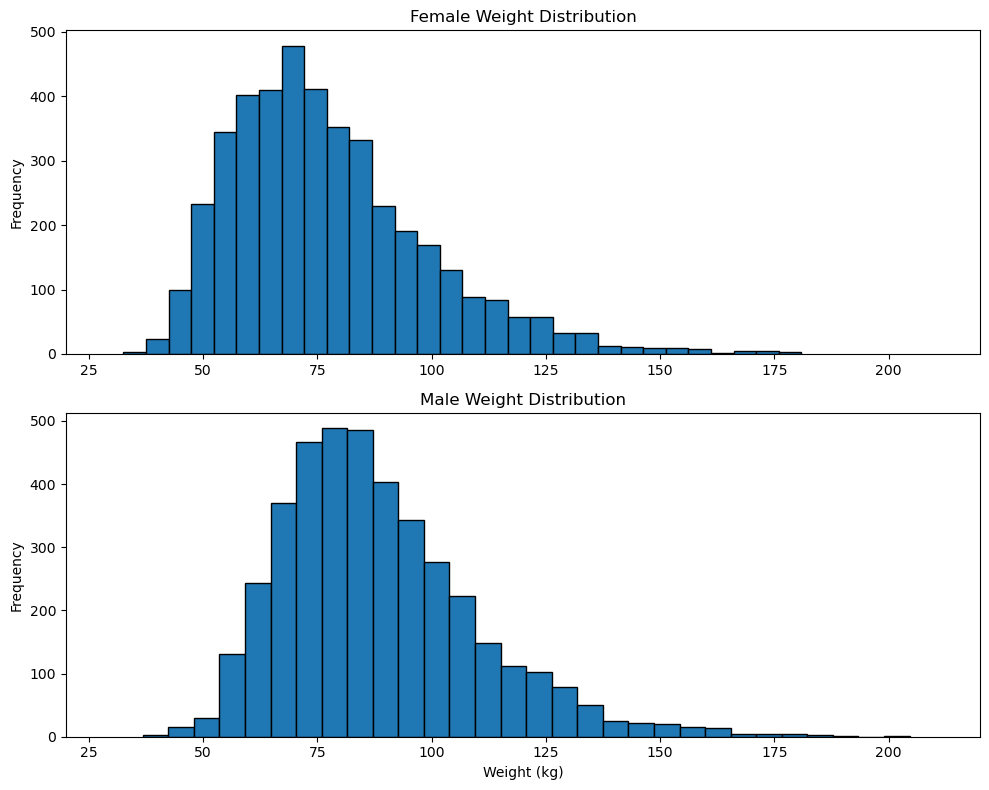

In [4]:
# Extract the weight column from both datasets
female_weights = female[:, 0]
male_weights = male[:, 0]

plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.hist(female_weights, bins=30, edgecolor="black")
plt.title("Female Weight Distribution")
plt.ylabel("Frequency")
plt.xlim(20, 220)

plt.subplot(2, 1, 2)
plt.hist(male_weights, bins=30, edgecolor="black")
plt.title("Male Weight Distribution")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.xlim(20, 220)

plt.tight_layout()
plt.show()

Both weight distributions show that most participants are concentrated around the lower and middle weight ranges, with fewer participants at higher weights. The male distribution is shifted towards higher weights compared to the female distribution. Both distributions are positively skewed, meaning they have longer tails towards heavier weights.

### Task 4: Comparing Weights Using Boxplots
A box-and-whisker plot is created to compare the distribution of male and female weights. This graph shows the median, quartiles, overall spread and potential outliers in both datasets.

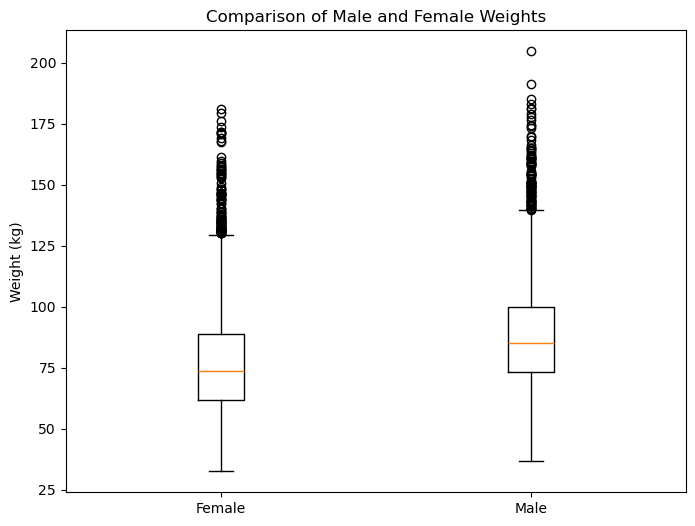

In [5]:
plt.figure(figsize=(8, 6))

plt.boxplot([female_weights, male_weights])

plt.xticks([1, 2], ["Female", "Male"])
plt.ylabel("Weight (kg)")
plt.title("Comparison of Male and Female Weights")

plt.show()

The boxplot shows that males generally have a higher median weight than females. Both groups have several outliers at the higher end of the weight distribution. The middle 50% of weights has a similar spread for males and females, suggesting that both groups have similar variation in their weights.

### Task 5: Descriptive Statistics of Weight
Descriptive statistics are calculated to compare male and female weights. These include measures of central tendency, such as the mean and median, measures of dispersion, such as standard deviation and variance, and measures of distribution shape, such as skewness and kurtosis.

In [6]:
def weight_stats(weights):
    return {
        "Mean": np.mean(weights),
        "Median": np.median(weights),
        "Minimum": np.min(weights),
        "Maximum": np.max(weights),
        "Range": np.ptp(weights),
        "Standard Deviation": np.std(weights),
        "Variance": np.var(weights),
        "IQR": np.percentile(weights, 75)
               - np.percentile(weights, 25),
        "Skewness": skew(weights),
        "Kurtosis": kurtosis(weights)
    }

stats = pd.DataFrame({
    "Female": weight_stats(female_weights),
    "Male": weight_stats(male_weights)
})

print(stats.round(2))

                    Female    Male
Mean                 77.40   88.36
Median               73.60   85.00
Minimum              32.60   36.80
Maximum             180.90  204.60
Range               148.30  167.80
Standard Deviation   21.54   21.42
Variance            464.08  458.77
IQR                  27.10   26.50
Skewness              1.03    0.98
Kurtosis              1.40    1.47


The average male weight is 88.36 kg, compared to 77.40 kg for females, showing a difference of approximately 10.96 kg. Both groups have similar standard deviations, with 21.54 kg for females and 21.42 kg for males. This indicates that their overall weight variation is similar. Both distributions have positive skewness, meaning that some participants have weights significantly higher than the average.

### Task 6: Calculating Body Mass Index (BMI)
The Body Mass Index (BMI) is calculated for each female participant using their weight in kilograms and height in metres. The calculated BMI values are then added as an eighth column to the female matrix.

In [7]:
female_bmi = female[:, 0] / (female[:, 1] / 100) ** 2

female = np.column_stack((female, female_bmi))

print("New shape:", female.shape)
print("Average BMI:", np.mean(female[:, 7]))

New shape: (4221, 8)
Average BMI: 30.10337881096128


The female matrix now contains eight columns instead of seven. The average BMI of female participants is approximately 30.10. This shows that the BMI calculation was successful and that the new measurements have been added to the dataset.

### Task 7: Standardising Female Body Measurements
The female body measurements are standardised using z-scores. Standardisation converts each measurement into a value showing how far it is from the mean in terms of standard deviations. This allows measurements with different units to be compared more easily.

In [8]:
female_mean = np.mean(female, axis=0)
female_std = np.std(female, axis=0)

# Calculate z-scores to standardise all female measurements
zfemale = (female - female_mean) / female_std

print("Shape:", zfemale.shape)
print("Column means:", np.round(zfemale.mean(axis=0), 3))
print("Column standard deviations:",
      np.round(zfemale.std(axis=0), 3))

Shape: (4221, 8)
Column means: [ 0.  0. -0. -0.  0. -0.  0. -0.]
Column standard deviations: [1. 1. 1. 1. 1. 1. 1. 1.]


The standardised dataset contains 4,221 rows and eight columns. All columns have a mean close to zero and a standard deviation of one. This confirms that the standardisation process was successful.

### Task 8: Scatterplot Matrix
A scatterplot matrix is created to examine the relationships between female height, weight, waist circumference, hip circumference and BMI. The standardised measurements are used to compare the variables and identify possible correlations.

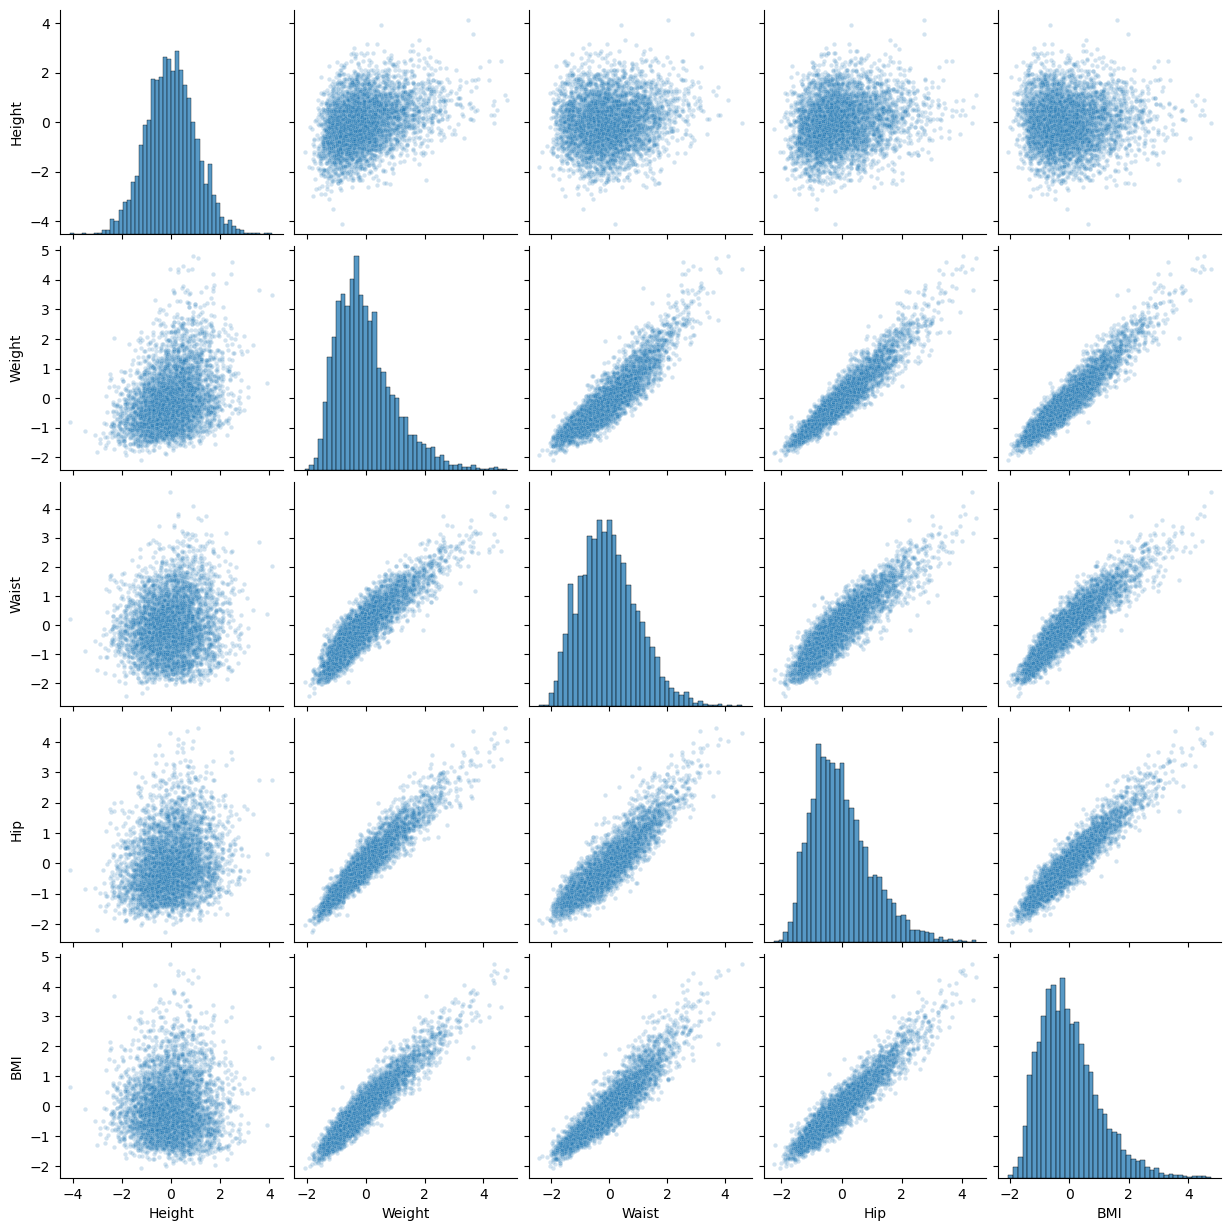

In [9]:
selected = zfemale[:, [1, 0, 6, 5, 7]]

columns = ["Height", "Weight", "Waist", "Hip", "BMI"]

df = pd.DataFrame(selected, columns=columns)

sns.pairplot(
    df,
    diag_kind="hist",
    plot_kws={"alpha": 0.2, "s": 10, "color": "tab:blue"},
    diag_kws={"color": "tab:blue"}
)

plt.show()

The scatterplots show strong positive relationships between weight, waist circumference, hip circumference and BMI. This means that participants with higher weights generally have larger body circumferences and higher BMI values. Height appears to have a weaker relationship with most of these measurements, particularly BMI.

### Pearson and Spearman Correlation Analysis
Pearson and Spearman correlation coefficients are calculated to measure the relationships between the selected female body measurements. Pearson correlation measures linear relationships, while Spearman correlation measures relationships based on the ranking of values.

In [10]:
pearson = df.corr(method="pearson")
spearman = df.corr(method="spearman")

print("Pearson Correlation:")
print(pearson.round(3))

print("Spearman Correlation:")
print(spearman.round(3))

Pearson Correlation:
        Height  Weight  Waist    Hip    BMI
Height   1.000   0.345  0.127  0.203  0.033
Weight   0.345   1.000  0.905  0.947  0.946
Waist    0.127   0.905  1.000  0.897  0.921
Hip      0.203   0.947  0.897  1.000  0.944
BMI      0.033   0.946  0.921  0.944  1.000
Spearman Correlation:
        Height  Weight  Waist    Hip    BMI
Height   1.000   0.339  0.109  0.205  0.020
Weight   0.339   1.000  0.900  0.947  0.938
Waist    0.109   0.900  1.000  0.888  0.923
Hip      0.205   0.947  0.888  1.000  0.934
BMI      0.020   0.938  0.923  0.934  1.000


The results show a strong positive correlation between weight and hip circumference, with a Pearson coefficient of 0.947. Weight and BMI also have a strong positive correlation of 0.946. However, height and BMI have a very weak correlation of 0.033, suggesting almost no linear relationship between these measurements. The Spearman results show similar patterns, supporting the relationships observed in the Pearson analysis.

### Task 9: Calculating Waist Ratios
The waist-to-height ratio and waist-to-hip ratio are calculated for both male and female participants. These ratios compare waist circumference with height and hip circumference. The results are added as two additional columns to each dataset.

In [11]:
female_whtr = female[:, 6] / female[:, 1]
female_whr = female[:, 6] / female[:, 5]

male_whtr = male[:, 6] / male[:, 1]
male_whr = male[:, 6] / male[:, 5]

female = np.column_stack(
    (female, female_whtr, female_whr)
)

male = np.column_stack(
    (male, male_whtr, male_whr)
)

print("Female shape:", female.shape)
print("Male shape:", male.shape)

Female shape: (4221, 10)
Male shape: (4081, 9)


Two new columns have been successfully added to both datasets. The female matrix now contains ten columns, while the male matrix contains nine columns. These additional measurements can be used to compare body proportions between male and female participants.

### Task 10: Comparing Waist Ratios
Four boxplots are created to compare the waist-to-height and waist-to-hip ratios of male and female participants. These graphs help identify differences in the median, spread and outliers of the two measurements.

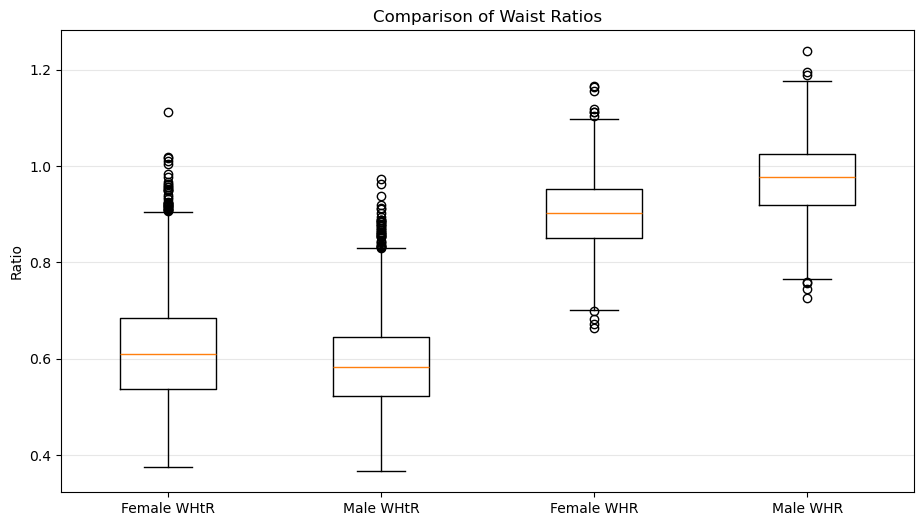

In [12]:
plt.figure(figsize=(11, 6))

plt.boxplot([
    female[:, 8],
    male[:, 7],
    female[:, 9],
    male[:, 8]
])

plt.xticks(
    [1, 2, 3, 4],
    ["Female WHtR", "Male WHtR",
     "Female WHR", "Male WHR"]
)

plt.ylabel("Ratio")
plt.title("Comparison of Waist Ratios")
plt.grid(axis="y", alpha=0.3)

plt.show()

The results show that females generally have a higher waist-to-height ratio, while males have a higher waist-to-hip ratio. This suggests that the two groups have different body proportions. Both ratios also show variation between participants, with some values appearing as outliers. These differences highlight why different body measurements can provide different information about body composition.

### Task 11: Advantages and Disadvantages of Body Measurements

**Body Mass Index (BMI)**

BMI is easy to calculate because it only requires a person's weight and height. It is commonly used to identify general weight categories. However, BMI does not distinguish between muscle and body fat, meaning that a muscular person may have a high BMI despite having low body fat.

**Waist-to-Height Ratio (WHtR)**

The waist-to-height ratio compares a person's waist circumference with their height. It can provide useful information about abdominal fat distribution and potential health risks. However, it does not directly measure body fat and can be affected by inaccurate waist measurements.

**Waist-to-Hip Ratio (WHR)**

The waist-to-hip ratio compares waist circumference with hip circumference. It helps identify differences in body fat distribution and can be useful for assessing health risks associated with abdominal fat. However, the results can be affected by differences in body shape and inaccurate measurements.

**Conclusion**

Each measurement has advantages and limitations. BMI is useful for general weight assessment, while waist-to-height and waist-to-hip ratios provide additional information about body proportions. Using multiple measurements can provide a more complete understanding of a person's body composition.

### Task 12: Identifying the Lowest and Highest BMI Values
The five female participants with the lowest BMI and the five with the highest BMI are identified using NumPy's argsort() function. Their standardised body measurements are displayed to compare participants at both ends of the BMI distribution.

In [13]:
# Sort female participants by BMI from lowest to highest
sorted_indices = np.argsort(female[:, 7])

lowest_5 = sorted_indices[:5]
highest_5 = sorted_indices[-5:][::-1]

selected_rows = np.concatenate(
    (lowest_5, highest_5)
)

print("Standardised measurements:")
print(np.round(zfemale[selected_rows], 2))

print("Original BMI values:")
print(np.round(female[selected_rows, 7], 2))

Standardised measurements:
[[-2.08 -1.22 -1.55 -1.17 -2.19 -2.04 -1.94 -2.05]
 [-1.88 -0.19 -1.72  0.39 -2.44 -1.85 -2.06 -1.99]
 [-1.54  1.81  0.63  0.57 -2.27 -1.68 -1.71 -1.97]
 [-1.84 -0.26 -0.23  0.51 -2.3  -2.25 -1.86 -1.94]
 [-1.61  0.89 -0.1   0.48 -2.21 -1.83 -1.71 -1.89]
 [ 4.36 -0.03 -0.06 -0.17  2.78  4.32  4.57  4.76]
 [ 4.8   0.89  2.12  1.82  3.78  4.02  4.08  4.54]
 [ 4.35  0.28  2.84  1.94  4.37  3.92  3.75  4.51]
 [ 4.46  0.5   1.69 -1.14  3.35  3.98  2.9   4.46]
 [ 4.25  0.29  1.86 -0.98  2.37  4.1   3.82  4.4 ]]
Original BMI values:
[14.2  14.63 14.82 15.04 15.42 67.04 65.33 65.12 64.71 64.2 ]


The five lowest BMI values range from 14.20 to 15.42, while the five highest range from 64.20 to 67.04. Participants with the lowest BMI values generally have negative z-scores for weight and body circumferences, indicating measurements below the average. Participants with the highest BMI values have large positive z-scores for weight and body circumferences. These results suggest a strong relationship between BMI, weight and body size.

## Overall Conclusion
This project compared body measurements from male and female NHANES participants using NumPy and statistical analysis. The results showed that males generally had higher body weights, while both groups had similar weight variation. The female dataset also showed strong relationships between weight, body circumferences and BMI. The analysis demonstrates how different statistical methods and visualisations can help identify patterns in body measurements.